# RC equivalents of the nightlight thermal and carrier equations

This notebook translates the reference equations before selecting a physical laser circuit. It separates **exact mathematical RC analogs**, **local fixed-RC approximations**, and **physical laser/BPW34 feasibility tests**. Controlled sources, voltage-dependent capacitors and controlled conductance in the reference diagrams are equation elements, not claims that ordinary passive parts implement them.

Source: the supplied [Optoelectronic Chaos paper](https://doi.org/10.1142/S0218127416500802), pp. 5–7, Eqs. (2), (3), (5), (6), Table 1. Its numerical thermal parameterization is used as printed: T₀=274.15 K, M=10⁻⁶, Rg=45.23, ΘD=310 K, a=0.0045549, b=5.77874×10⁻¹⁰, σ=1.74×10⁻¹³, R₀=250 Ω; τe=10⁻¹² s, c=0.454, ψ=0.44. The printed mass/specific-heat units need reconciliation before treating these coefficients as a measured physical heat capacity. The text calls 110 V an RMS mains voltage while the table calls it an amplitude. Neither ambiguity is silently corrected here: the DC operating voltage is calculated from a stated 2200 K operating point, and independent bulb-voltage inputs are used for block tests. No mains hardware experiment is proposed.

The laser experiment retains BPW34, not a CdS photoresistor. Matching the reference carrier state is a comparison task; it does not replace the measured/fitted BPW34 current law. No inductor is used in these RC translations, and no chaos or complete nightlight reproduction is claimed.


,temperature_K,heating_W,filament_ohm,voltage_V,capacity_model_units,radiation_slope_W_K,cooling_time_s,voltage_driven_time_s,temp_state_capacitance_F,temp_state_tangent_R_ohm,temp_state_voltage_driven_R_ohm,power_state_R_ohm,power_state_hot_C_F
0,2200.0,4.075072,3042.71535,111.352066,0.00018,0.007411,0.024316,0.018706,0.00018,134.934411,103.801477,10000.0,0.000002


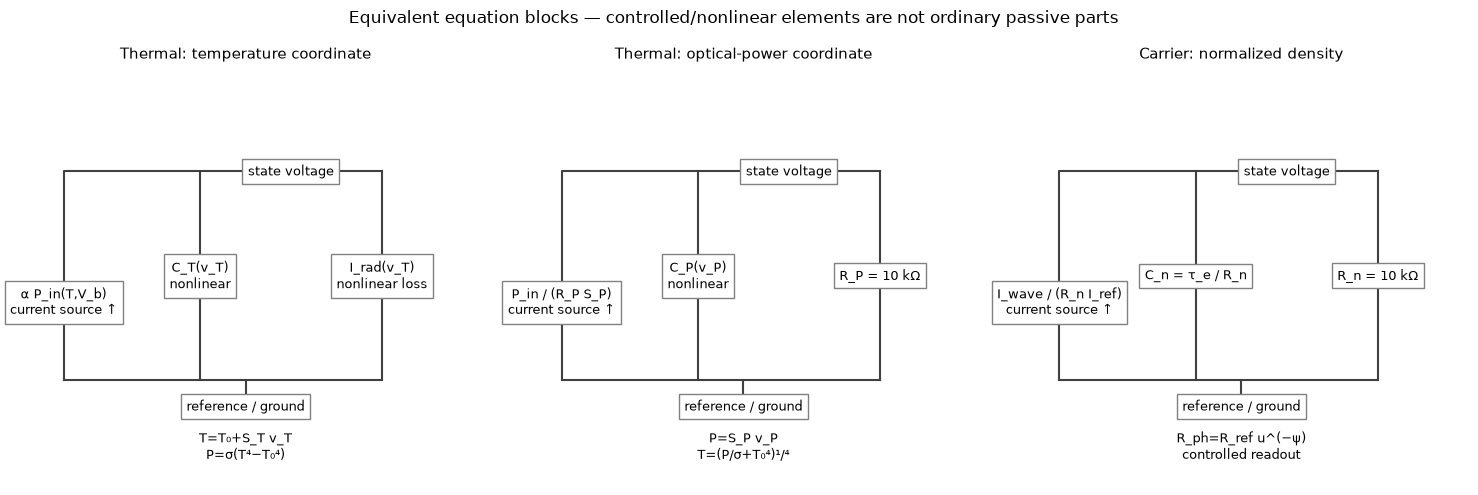

In [1]:
from pathlib import Path
import os,sys,json,hashlib
from dataclasses import asdict,replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import minimize_scalar,brentq
from IPython.display import display,Markdown
ROOT=Path(os.environ.get('TWIN_PROJECT_ROOT','.'))
sys.path.insert(0,os.environ.get('TWIN_COMPONENT_PATH',str(ROOT/'03_code')))
from twin_components.nightlight_rc_equivalents import ThermalRCEquivalent,CarrierRCEquivalent,LaserParallelCapBench,ThermallyMatchedLaserCapBench
from twin_components.single_transistor_rlc import SingleTransistorRLC
from twin_components.delayed_latch_optics import cycle_metrics
OUTPUT=Path(os.environ.get('TWIN_OUTPUT_ROOT',str(ROOT)))
OUT=OUTPUT/'03_code/notebooks/twin_output/nightlight_rc_blocks';OUT.mkdir(parents=True,exist_ok=True)
FIG=OUTPUT/'06_figures';FIG.mkdir(parents=True,exist_ok=True)
raw=ROOT/'02_data/hysteresis_experiment_0.csv';raw_hash=hashlib.sha256(raw.read_bytes()).hexdigest()
thermal=ThermalRCEquivalent();carrier=CarrierRCEquivalent();op=thermal.operating_point(2200.);Veq=op['voltage_V']
pd.DataFrame([asdict(thermal.p)]).to_csv(OUT/'reference_parameters.csv',index=False)
display(pd.DataFrame([op]));pd.DataFrame([op]).to_csv(OUT/'reference_operating_point.csv',index=False)
def save(fig,name):
    for ext in ['png','svg']:fig.savefig(FIG/(name+'.'+ext),dpi=180,bbox_inches='tight')
    plt.show()
fig,axs=plt.subplots(1,3,figsize=(15,5))
titles=['Thermal: temperature coordinate','Thermal: optical-power coordinate','Carrier: normalized density']
caps=['C_T(v_T)\nnonlinear','C_P(v_P)\nnonlinear','C_n = τ_e / R_n']
losses=['I_rad(v_T)\nnonlinear loss','R_P = 10 kΩ','R_n = 10 kΩ']
sources=['α P_in(T,V_b)','P_in / (R_P S_P)','I_wave / (R_n I_ref)']
readouts=['T=T₀+S_T v_T\nP=σ(T⁴−T₀⁴)','P=S_P v_P\nT=(P/σ+T₀⁴)¹/⁴','R_ph=R_ref u^(−ψ)\ncontrolled readout']
for ax,title,cap,loss,source,readout in zip(axs,titles,caps,losses,sources,readouts):
    ax.axis('off');ax.set(xlim=(0,10),ylim=(0,8));ax.set_title(title,fontsize=11)
    def wire(x,y):ax.plot(x,y,color='.25',lw=1.5)
    def box(x,y,s):ax.text(x,y,s,ha='center',va='center',fontsize=9,bbox=dict(facecolor='white',edgecolor='.5',pad=4))
    wire([1,1,8],[2,6,6]);box(1,3.5,source+'\ncurrent source ↑')
    wire([4,4],[6,2]);wire([8,8],[6,2]);wire([1,8],[2,2]);wire([5,5],[2,1.5]);box(5,1.5,'reference / ground')
    box(4,4,cap);box(8,4,loss);box(6,6,'state voltage');ax.text(5,.5,readout,ha='center',fontsize=9)
fig.suptitle('Equivalent equation blocks — controlled/nonlinear elements are not ordinary passive parts')
fig.tight_layout();save(fig,'nightlight_rc_equivalent_schematics')


## 1. Thermal equation → two equivalent nonlinear RC descriptions

Write the reference equation as
$$C_{th}(T)\dot T=P_{in}(T,V_b)-P_{rad}(T),\quad C_{th}=MC(T),$$
$$P_{in}=V_b^2/R_f(T),\quad R_f(T)=R_0(T/T_0)^{1.2},\quad P_{rad}=\sigma(T^4-T_0^4).$$

**Temperature-state analog.** Choose T=T₀+S_T v_T and current scale α A per model watt. Then
$$C_T(v_T)=\alpha S_T C_{th}(T),\quad I_{heat}=\alpha P_{in},\quad I_{loss}=\alpha P_{rad},$$
$$C_T(v_T)\dot v_T=I_{heat}-I_{loss}.$$
C_T is a **differential capacitance**, dQ/dv. The loss element is nonlinear, with nonnegative conductance above ambient; the heating source also depends on state through Rf(T). Voltage represents temperature and capacitor charge represents scaled heat content. Electrical capacitor energy is not automatically the bulb's stored thermal energy.

**Optical-power-state analog.** A more direct output coordinate is P=S_P v_P. Since dP/dT=4σT³,
$$\tau_P(T)\dot P=P_{in}-P,\qquad\tau_P(T)=C_{th}(T)/(4\sigma T^3).$$
Choose any R_P and set
$$C_P(v_P)=\tau_P(T(P))/R_P,\qquad I_{heat}=P_{in}/(R_P S_P).$$
The resistor is now fixed and capacitance carries the nonlinear dependence. With R_P=10 kΩ, the hot-state C_P is about 2.43 µF, but it increases to about 903 µF near ambient. It is not a single fixed 2.43 µF equivalent over the full range.

**Local fixed RC.** At T*=2200 K, cooling under an independently specified heating-power input has τ≈24.32 ms. Under constant bulb-voltage boundary conditions, Rf(T) creates additional negative feedback: the local pole time is Cth/[4σT³+1.2Pin/T]≈18.71 ms. These are different boundary conditions, not competing estimates. A 1% voltage step below checks the local approximation.


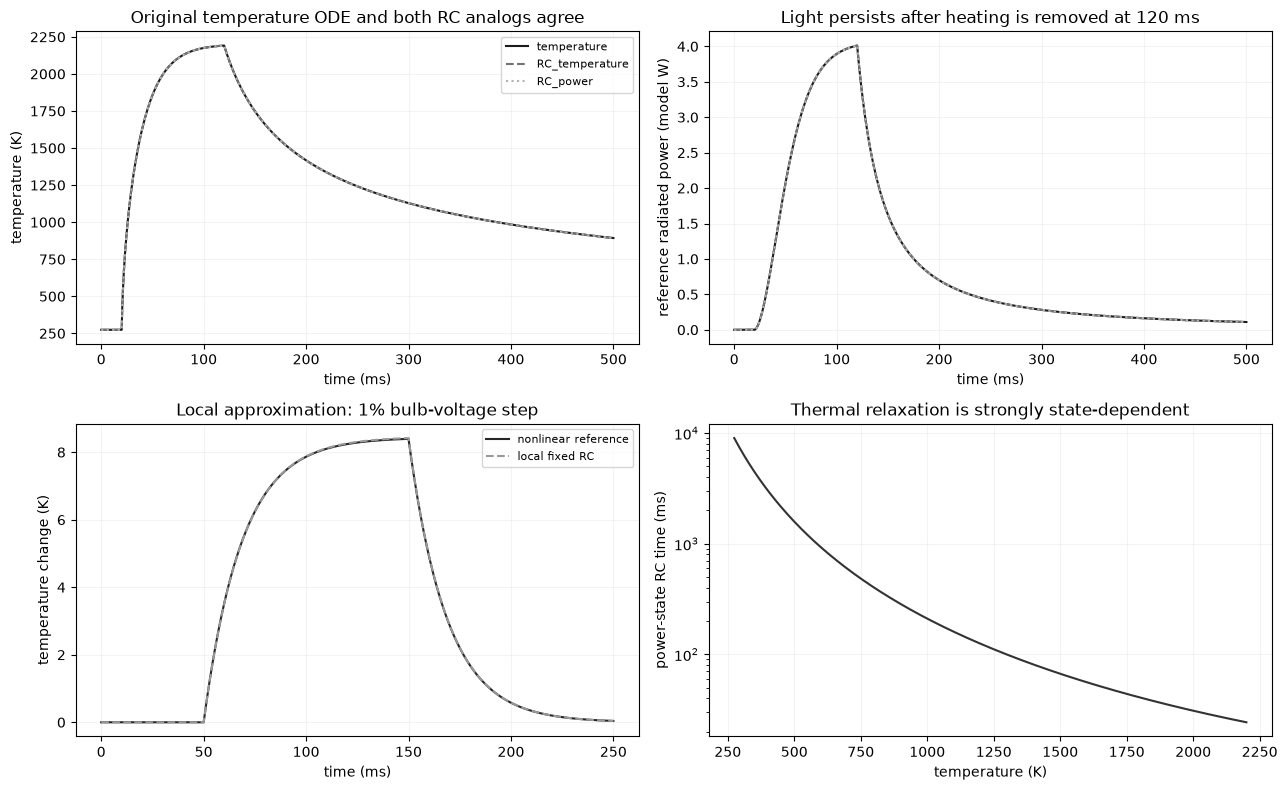

,RC_temperature,RC_power,local_small_step_relative_error
0,7.323713e-07,0.000001,0.002815


In [2]:
t=np.linspace(0,.5,5001);pulse=lambda s:Veq if .02<=s<.12 else 0.
large={}
for coord in ['temperature','RC_temperature','RC_power']:
    f=thermal.run(t,pulse,coordinate=coord,breaks=[.02,.12]);large[coord]=f;f.to_csv(OUT/('large_'+coord+'.csv'),index=False)
ts=np.linspace(0,.25,2501);small_input=lambda s:Veq*(1.01 if .05<=s<.15 else 1.)
small=thermal.run(ts,small_input,initial_K=2200.);small.to_csv(OUT/'small_voltage_step.csv',index=False)
tau=op['voltage_driven_time_s'];sensitivity=(2*Veq/op['filament_ohm'])/(op['radiation_slope_W_K']+1.2*op['heating_W']/2200.)
delta_ss=sensitivity*(.01*Veq)
delta=np.where(ts<.05,0.,np.where(ts<.15,delta_ss*(1-np.exp(-np.maximum(ts-.05,0)/tau)),delta_ss*(1-np.exp(-.1/tau))*np.exp(-np.maximum(ts-.15,0)/tau)))
thermal_errors={coord:float(np.max(abs(f.temperature_K-large['temperature'].temperature_K))) for coord,f in large.items() if coord!='temperature'}
linear_error=float(np.max(abs((small.temperature_K-2200.)-delta))/delta_ss)
fig,axs=plt.subplots(2,2,figsize=(13,8))
for coord,color,ls in [('temperature','.1','-'),('RC_temperature','.45','--'),('RC_power','.7',':')]:
    f=large[coord];axs[0,0].plot(f.time_s*1e3,f.temperature_K,color=color,ls=ls,label=coord)
    axs[0,1].plot(f.time_s*1e3,f.optical_W,color=color,ls=ls,label=coord)
axs[0,0].set(title='Original temperature ODE and both RC analogs agree',xlabel='time (ms)',ylabel='temperature (K)');axs[0,0].legend(fontsize=8)
axs[0,1].set(title='Light persists after heating is removed at 120 ms',xlabel='time (ms)',ylabel='reference radiated power (model W)')
axs[1,0].plot(ts*1e3,small.temperature_K-2200,color='.15',label='nonlinear reference')
axs[1,0].plot(ts*1e3,delta,color='.6',ls='--',label='local fixed RC');axs[1,0].set(title='Local approximation: 1% bulb-voltage step',xlabel='time (ms)',ylabel='temperature change (K)');axs[1,0].legend(fontsize=8)
tt=np.linspace(thermal.p.ambient_K,2200,300)
axs[1,1].semilogy(tt,thermal.power_time_s(tt)*1e3,color='.2');axs[1,1].set(title='Thermal relaxation is strongly state-dependent',xlabel='temperature (K)',ylabel='power-state RC time (ms)')
for ax in axs.flat:ax.grid(alpha=.15)
fig.tight_layout();save(fig,'nightlight_rc_thermal_translation')
display(pd.DataFrame([dict(**thermal_errors,local_small_step_relative_error=linear_error)]))


## 2. Carrier equation → linear RC, nonlinear resistance readout

From $\dot n=I_{wave}-n/\tau_e$, define $u=n/(\tau_e I_*)$. Then
$$\tau_e\dot u=I_{wave}/I_*-u.$$
Represent u by a node voltage, choose Rn, and set Cn=τe/Rn. A light-controlled current Iwave/(Rn I*) drives that node; resistor current u/Rn supplies recombination. This is an exact linear RC state equation. Its output remains **nonlinear**:
$$R_{ph}=R_*u^{-\psi},\quad R_*=c/(\tau_e I_*)^\psi.$$
The RC resistor Rn and the controlled photoresistance Rph are different elements. An RC pair alone does not implement the variable resistance readout.

For the printed τe=1 ps and Rn=10 kΩ, Cn=0.1 fF. That is a symbolic analog value, far below BPW34's intrinsic junction capacitance. At 60 Hz, ωτe≈3.77×10⁻¹⁰: the reference carrier state is effectively quasi-static. There is no justification for adding a millisecond PD delay and calling it this printed carrier model. BPW34 also has its own current/charge/collection laws; the CdS readout is not being substituted into the laser board.

Changing τe while keeping c fixed also changes the DC photoresistance. A hypothetical slower-carrier study must explicitly preserve or recalibrate the static law. The helper below rescales c to preserve R*; it is a parameter-control demonstration, not a fit to the unidentified reference photoresistor.


,case,tau_s,R_ohm,C_F,Rref_ohm,c
0,paper as printed,1.000000e-12,10000.0,1.000000e-16,86507.916596,0.454000
1,"hypothetical slower state, same DC readout",1.000000e-02,10000.0,1.000000e-06,86507.916596,11403.964399


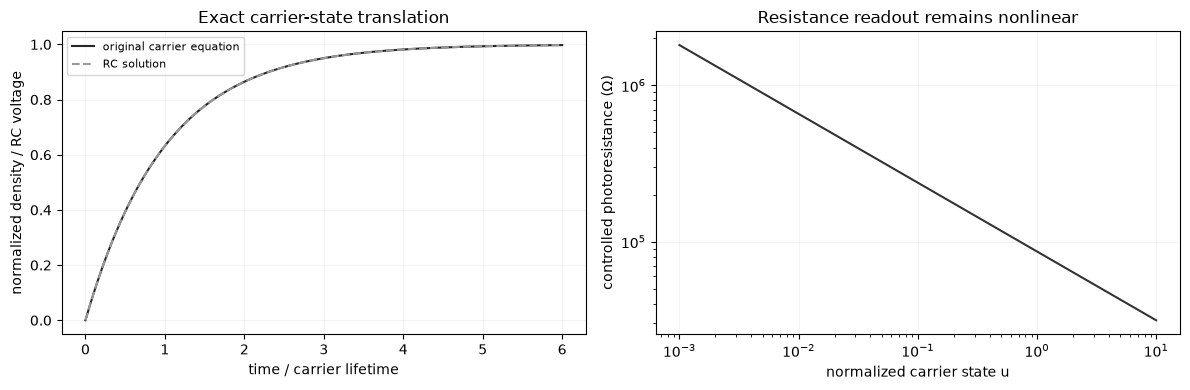

In [3]:
tau_n=thermal.p.carrier_lifetime_s;ss=np.linspace(0,6,601);times=ss*tau_n
sol=solve_ivp(lambda s,n:[1.-n[0]/tau_n],(0,times[-1]),[0.],rtol=1e-10,atol=1e-24,max_step=tau_n/50,dense_output=True)
n=sol.sol(times)[0];u_direct=n/tau_n;u_rc=1-np.exp(-ss)
carrier_error=float(np.max(abs(u_direct-u_rc)))
c_slow=carrier.c_for_preserved_DC_curve(.01)
slow_carrier=CarrierRCEquivalent(parameters=replace(thermal.p,carrier_lifetime_s=.01,photo_c=c_slow))
grid_u=np.geomspace(.001,10,200)
dc_curve_error=float(np.max(abs(slow_carrier.conductance(grid_u)/carrier.conductance(grid_u)-1)))
pd.DataFrame(dict(time_s=times,time_over_tau=ss,normalized_density_direct=u_direct,RC_voltage=u_rc)).to_csv(OUT/'carrier_step.csv',index=False)
carrier_table=pd.DataFrame([dict(case='paper as printed',tau_s=tau_n,R_ohm=carrier.R,C_F=carrier.C,Rref_ohm=carrier.Rref,c=thermal.p.photo_c),dict(case='hypothetical slower state, same DC readout',tau_s=.01,R_ohm=slow_carrier.R,C_F=slow_carrier.C,Rref_ohm=slow_carrier.Rref,c=c_slow)])
display(carrier_table);carrier_table.to_csv(OUT/'carrier_scaling.csv',index=False)
fig,axs=plt.subplots(1,2,figsize=(12,4))
axs[0].plot(ss,u_direct,color='.15',label='original carrier equation');axs[0].plot(ss,u_rc,color='.6',ls='--',label='RC solution');axs[0].set(xlabel='time / carrier lifetime',ylabel='normalized density / RC voltage',title='Exact carrier-state translation');axs[0].legend(fontsize=8)
axs[1].loglog(grid_u,1/carrier.conductance(grid_u),color='.2');axs[1].set(xlabel='normalized carrier state u',ylabel='controlled photoresistance (Ω)',title='Resistance readout remains nonlinear')
for ax in axs:ax.grid(alpha=.15)
fig.tight_layout();save(fig,'nightlight_rc_carrier_translation')


## 3. Physical emitter storage: a capacitor across the laser branch

Thermal storage lets the bulb emit after its electrical drive is removed. Storage only at the photodiode or base does not automatically give that behavior: if the collector supply collapses, the laser still loses power. This isolated component test places a capacitor **across the laser plus ballast branch**, so it can discharge through that branch after charging current ends.

The bench input is a specified return/collector current: C_L dV/dt=Icharge−IL(V). It is an explicit unit-test input, not a prediction of a complete transistor feedback circuit. In a low-side implementation with a falling upper rail, an **output isolation diode** is required between the floating load return and Q1 collector; otherwise the stored voltage can drive that collector negative and forward-bias its junctions. That extra topology has not been integrated into the complete laser-board model here. No low-side wiring change is claimed validated by this unit test.

The initial current is 35 mA, within the existing mathematical laser domain. A fixed capacitor is fitted only to the normalized 0–80 ms optical cooling curve. The same value is then tested for warming with a 35 mA current limit. This exposes the difference between matching one decay and matching both heating/cooling.

An exact cooling-only translation into the laser's own nonlinear I–V/L–I laws is also possible. Let Plaser=f(V), β=Plaser(0)/Preference(0), and T=T(Plaser/β). Then
$$C_{L,required}(V)=\frac{I_L(V)f'(V)\tau_P(T)}{f(V)}.$$
This voltage-dependent capacitance makes the scaled optical cooling equations agree. It is a mathematical reference, **not an identified available capacitor**. Matching heating additionally requires Icharge=IL βPin/f(V), not an arbitrary fixed charging current. The warm-up current requirement and actual source limits still matter.


,block,time_10_s,time_90_s
0,reference thermal,0.01000,0.06450
1,"laser + fitted fixed C, 35mA limit",0.48975,0.94825


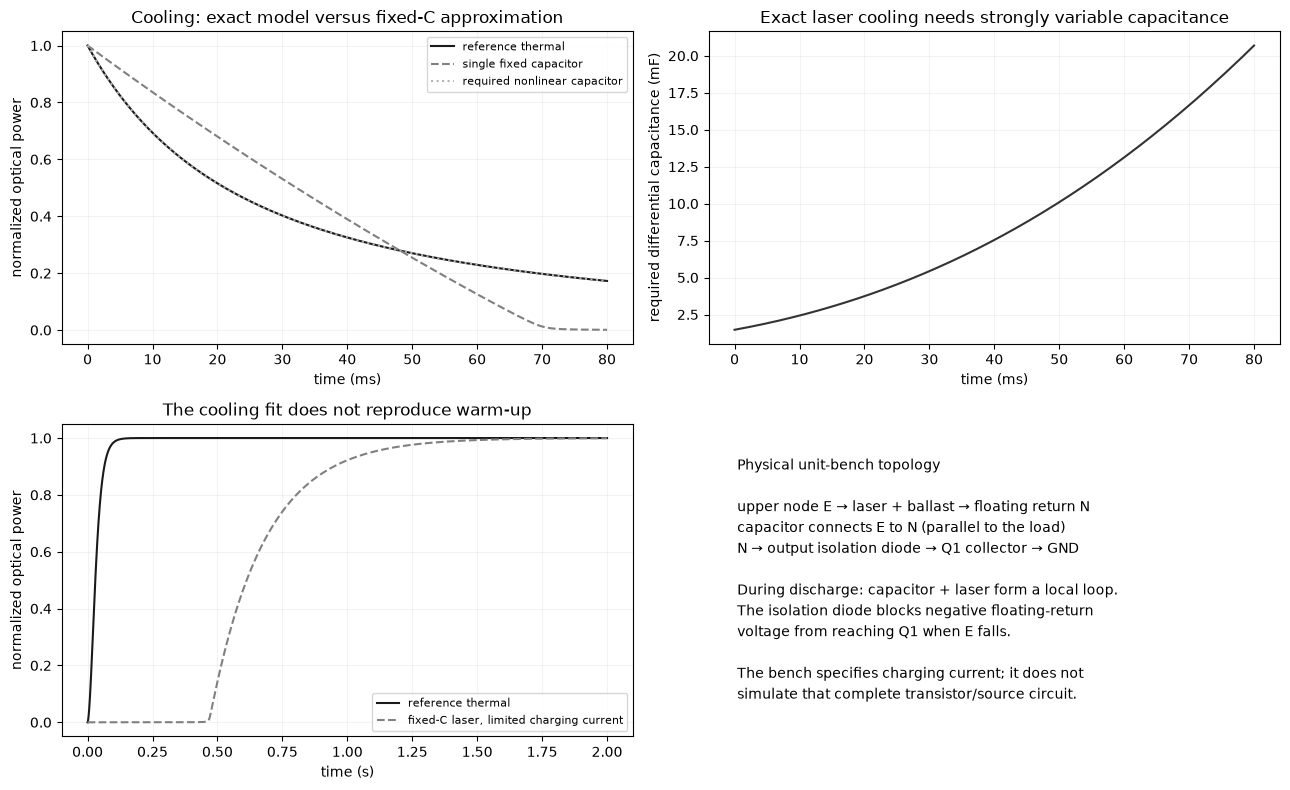

In [4]:
tc=np.linspace(0,.08,1601);cool=thermal.run(tc,lambda s:0.,initial_K=2200.);cool.to_csv(OUT/'thermal_cooling.csv',index=False)
target=cool.optical_W.to_numpy()/cool.optical_W.iloc[0]
def objective(logc):
    b=LaserParallelCapBench(np.exp(logc));f=b.run(tc,lambda s:0.,initial_V=b.voltage_for_current(.035))
    return float(np.mean((f.laser_W/f.laser_W.iloc[0]-target)**2))
fit=minimize_scalar(objective,bounds=(np.log(10e-6),np.log(.02)),method='bounded',options={'xatol':1e-7})
fitted_C=float(np.exp(fit.x));bench=LaserParallelCapBench(fitted_C)
fixed=bench.run(tc,lambda s:0.,initial_V=bench.voltage_for_current(.035));fixed.to_csv(OUT/'laser_fixed_cap_cooling.csv',index=False)
nonlinear_bench=ThermallyMatchedLaserCapBench(thermal);matched=nonlinear_bench.run_cooling(tc);matched.to_csv(OUT/'laser_nonlinear_cap_cooling.csv',index=False)
nonlinear_error=float(np.sqrt(np.mean((matched.laser_W/matched.laser_W.iloc[0]-target)**2)))
tw=np.linspace(0,2.,8001);warm=thermal.run(tw,lambda s:Veq);lw=bench.run(tw,lambda s:.035)
warm.to_csv(OUT/'thermal_warming.csv',index=False);lw.to_csv(OUT/'laser_fixed_cap_warming.csv',index=False)
laser_final=float(bench.laser.dc(.035)['power_W'])
def crossing(f,col,level):
    q=f[f[col]>=level];return float(q.time_s.iloc[0]) if len(q) else None
rise_table=pd.DataFrame([dict(block='reference thermal',time_10_s=crossing(warm,'optical_W',.1*op['heating_W']),time_90_s=crossing(warm,'optical_W',.9*op['heating_W'])),dict(block='laser + fitted fixed C, 35mA limit',time_10_s=crossing(lw,'laser_W',.1*laser_final),time_90_s=crossing(lw,'laser_W',.9*laser_final))])
display(rise_table);rise_table.to_csv(OUT/'emitter_rise_comparison.csv',index=False)
fig,axs=plt.subplots(2,2,figsize=(13,8))
axs[0,0].plot(tc*1e3,target,color='.1',label='reference thermal');axs[0,0].plot(tc*1e3,fixed.laser_W/fixed.laser_W.iloc[0],color='.5',ls='--',label='single fixed capacitor');axs[0,0].plot(tc*1e3,matched.laser_W/matched.laser_W.iloc[0],color='.7',ls=':',label='required nonlinear capacitor');axs[0,0].set(title='Cooling: exact model versus fixed-C approximation',xlabel='time (ms)',ylabel='normalized optical power');axs[0,0].legend(fontsize=8)
axs[0,1].plot(tc*1e3,matched.required_capacitance_F*1e3,color='.2');axs[0,1].set(title='Exact laser cooling needs strongly variable capacitance',xlabel='time (ms)',ylabel='required differential capacitance (mF)')
axs[1,0].plot(tw,warm.optical_W/op['heating_W'],color='.1',label='reference thermal');axs[1,0].plot(tw,lw.laser_W/laser_final,color='.5',ls='--',label='fixed-C laser, limited charging current');axs[1,0].set(title='The cooling fit does not reproduce warm-up',xlabel='time (s)',ylabel='normalized optical power');axs[1,0].legend(fontsize=8)
axs[1,1].axis('off');axs[1,1].text(.05,.9,'Physical unit-bench topology\n\nupper node E → laser + ballast → floating return N\ncapacitor connects E to N (parallel to the load)\nN → output isolation diode → Q1 collector → GND\n\nDuring discharge: capacitor + laser form a local loop.\nThe isolation diode blocks negative floating-return\nvoltage from reaching Q1 when E falls.\n\nThe bench specifies charging current; it does not\nsimulate that complete transistor/source circuit.',va='top',fontsize=10,linespacing=1.5)
for ax in axs.flat[:3]:ax.grid(alpha=.15)
fig.tight_layout();save(fig,'nightlight_rc_laser_emitter_feasibility')


## 4. Loading test in the existing one-NPN RC-only circuit

An ordinary base capacitor is another possible local emitter-drive approximation. This test uses the existing **one-NPN circuit with L=0, no added PD capacitor, 1 kΩ feedback resistance and 5 V DC**, beam blocked. The complete fitted transistor/laser/PD laws remain active. The base capacitor is selected so the slow linearized pole equals the reference **18.71 ms voltage-driven pole** at its dark DC point.

This is a loaded circuit fit: the equivalent input resistance includes transistor conduction and feedback paths, not just the 10 kΩ drive resistor. Its calculated effective resistance is not an extra resistor to solder into the circuit. A 20 µV base perturbation checks the local fit; a 1 mV perturbation demonstrates departure from that linearization. This does not reproduce the nonlinear thermal block globally.

A separate 60 Hz self-feedback trace starts from a stated precharged DC self-feedback state. It tests the direct base-RC placement, not a finished thermal-equivalent laser. In this topology optical feedback drains the base memory, and the laser collector rail still falls with the source. A closer thermal surrogate must let light inhibit charging/heating **without directly erasing stored emitter energy**, and must provide an energy path for optical decay after drive removal.


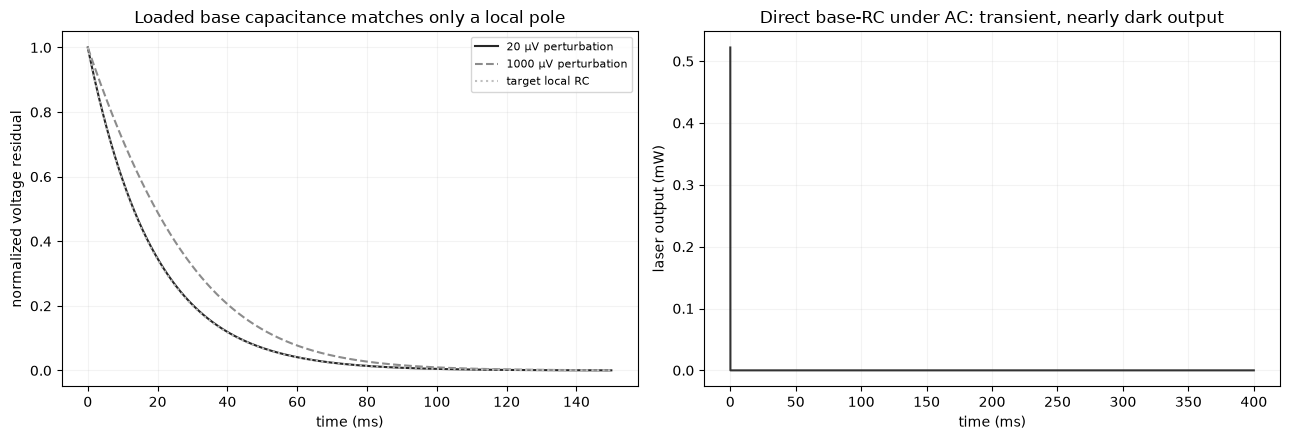

,fitted_base_C_uF,loaded_effective_R_ohm,target_pole_time_ms,normalized_RMS_20uV,normalized_RMS_1mV
0,723.725627,25.846852,18.706029,0.001418,0.066379


In [5]:
base=SingleTransistorRLC(L_H=0.,C_pd_F=0.,C_base_F=0.,R_feedback=1e3,coupling=0.,supply='DC');devices=base.devices
eqframe=base.run(np.linspace(0,.01,201),initial=[0,4.5,0,4.5,0],max_step=.0001)
statecols=['base_V','collector_V','trigger_V','rail_V','diode_V'];eq=eqframe[statecols].iloc[-1].to_numpy()
def slowest(cap):
    base.Cb=cap;eps=1e-6
    J=np.column_stack([(base.point(0,eq+np.eye(5)[j]*eps)['rates']-base.point(0,eq-np.eye(5)[j]*eps)['rates'])/(2*eps) for j in range(5)])
    return float(max(np.linalg.eigvals(J).real))
base_C=brentq(lambda c:slowest(c)+1/tau,1e-9,.01,xtol=1e-12);base.Cb=base_C
tp=np.unique(np.r_[np.linspace(0,10e-6,101),np.linspace(10e-6,.15,1501)])
probes={}
for delta in [20e-6,.001]:
    initial=eq.copy();initial[0]-=delta
    f=base.run(tp,initial=initial,rtol=2e-9,max_step=.0001);probes[delta]=f
    f.to_csv(OUT/f'loaded_base_probe_{delta:g}V.csv',index=False)
mask=tp>1e-5
probe_errors={str(delta):float(np.sqrt(np.mean(((eq[0]-f.base_V.to_numpy()[mask])/delta-np.exp(-tp[mask]/tau))**2))) for delta,f in probes.items()}
dcself=SingleTransistorRLC(L_H=0.,C_pd_F=0.,R_feedback=1e3,coupling=.8,supply='DC',devices=devices)
dcs=dcself.run(np.linspace(0,.02,401),initial=[0,4.5,0,4.5,0],max_step=.0001)
ac=SingleTransistorRLC(L_H=0.,C_pd_F=0.,C_base_F=base_C,R_feedback=1e3,coupling=.8,supply='AC',devices=devices)
af=ac.run(np.linspace(0,24/60,24001),initial=dcs[statecols].iloc[-1].to_numpy());af.to_csv(OUT/'loaded_base_RC_AC_self.csv',index=False)
ac_cycles,ac_info=cycle_metrics(af,discard_cycles=18,samples_per_cycle=1000)
fig,axs=plt.subplots(1,2,figsize=(13,4.5))
for delta,color,ls in [(20e-6,'.15','-'),(.001,'.55','--')]:
    f=probes[delta];axs[0].plot(f.time_s*1e3,(eq[0]-f.base_V)/delta,color=color,ls=ls,label=f'{delta*1e6:g} µV perturbation')
axs[0].plot(tp*1e3,np.exp(-tp/tau),color='.75',ls=':',label='target local RC');axs[0].set(title='Loaded base capacitance matches only a local pole',xlabel='time (ms)',ylabel='normalized voltage residual');axs[0].legend(fontsize=8)
axs[1].plot(af.time_s*1e3,af.laser_W*1e3,color='.2');axs[1].set(title='Direct base-RC under AC: transient, nearly dark output',xlabel='time (ms)',ylabel='laser output (mW)')
for ax in axs:ax.grid(alpha=.15)
fig.tight_layout();save(fig,'nightlight_rc_loaded_base_test')
display(pd.DataFrame([dict(fitted_base_C_uF=base_C*1e6,loaded_effective_R_ohm=tau/base_C,target_pole_time_ms=tau*1e3,normalized_RMS_20uV=probe_errors[str(20e-6)],normalized_RMS_1mV=probe_errors[str(.001)])]))


## 5. Connected RC switching experiment: one NPN, BPW34 and laser

This section tests switching with the devices connected, beyond the separate equation-block tests above. It is a **physical fixed-capacitor candidate**, not the exact nonlinear thermal equivalent and not an SCR replacement.

The supply is ideal **5 V DC**. Q1 is the fitted 2N3904 with emitter grounded. The laser plus 33 Ω external ballast connect from +5 V to Q1 collector X. A **3.595 mF capacitor connects between +5 V and X**, in parallel with that entire load branch. The laser model retains its internal resistance. The base connects to +5 V through 10 kΩ and to ground through 100 kΩ. A 1 kΩ resistor connects the base to the BPW34 cathode; its anode is grounded. There is **no base capacitor, inductor, comparator, timer, or latched switch state** in this candidate. These are proposed test connections rather than a claim about the photographed board.

```text
                     +5 V DC
                  ┌─────┴─────┐
              laser + 33 Ω    C = 3.595 mF
                  └─────┬─────┘
                        X = Q1 collector
                        Q1 emitter ── GND

+5 V ── 10 kΩ ── Q1 base ── 1 kΩ ── BPW34 cathode
                     │                BPW34 anode ── GND
                   100 kΩ
                     │
                    GND
```

With v=5−V_X, the energy-storage equation is
$$C\dot v=I_C(V_B,V_X)-I_L(v),\qquad E_C=\tfrac12 Cv^2.$$
Base and detector voltages are solved from their simultaneous current balances at each time step:
$$I_{drive}=I_B+V_B/(100\,\mathrm{k\Omega})+(V_B-V_D)/(1\,\mathrm{k\Omega}),$$
$$(V_B-V_D)/(1\,\mathrm{k\Omega})=I_{PD}(V_D,P_{inc}).$$
The inherited transistor and BPW34 equations determine these currents, including photodiode forward conduction. Junction dynamics are treated as quasi-static relative to this large capacitor; no additional slow carrier time is assigned. The emitter capacitor supplies a local discharge loop through the laser when Q1 stops sinking current. Collector current falls promptly, while optical output decays as stored energy is depleted.

Three experiments begin with an uncharged capacitor: (1) disconnect only the 10 kΩ base feed from 2–4 s while retaining the collector supply, (2) apply 5 mW external detector illumination from 2–4 s, and (3) send 50% of the laser output back to its own BPW34 continuously. The first two use no self-return beam. A capacitor ten times smaller is a timing control in experiment 2. External illumination is a test stimulus; no prescribed on/off state is imposed on Q1.


,test,off_90_to_10_ms,off_to_10_ms,on_10_to_90_ms,on_to_90_ms
0,feed removed,105.654906,115.767640,428.075617,618.135100
1,light applied,105.654906,115.767640,428.075617,618.135100
2,"light applied, C/10",10.557986,11.593427,42.822819,63.053744


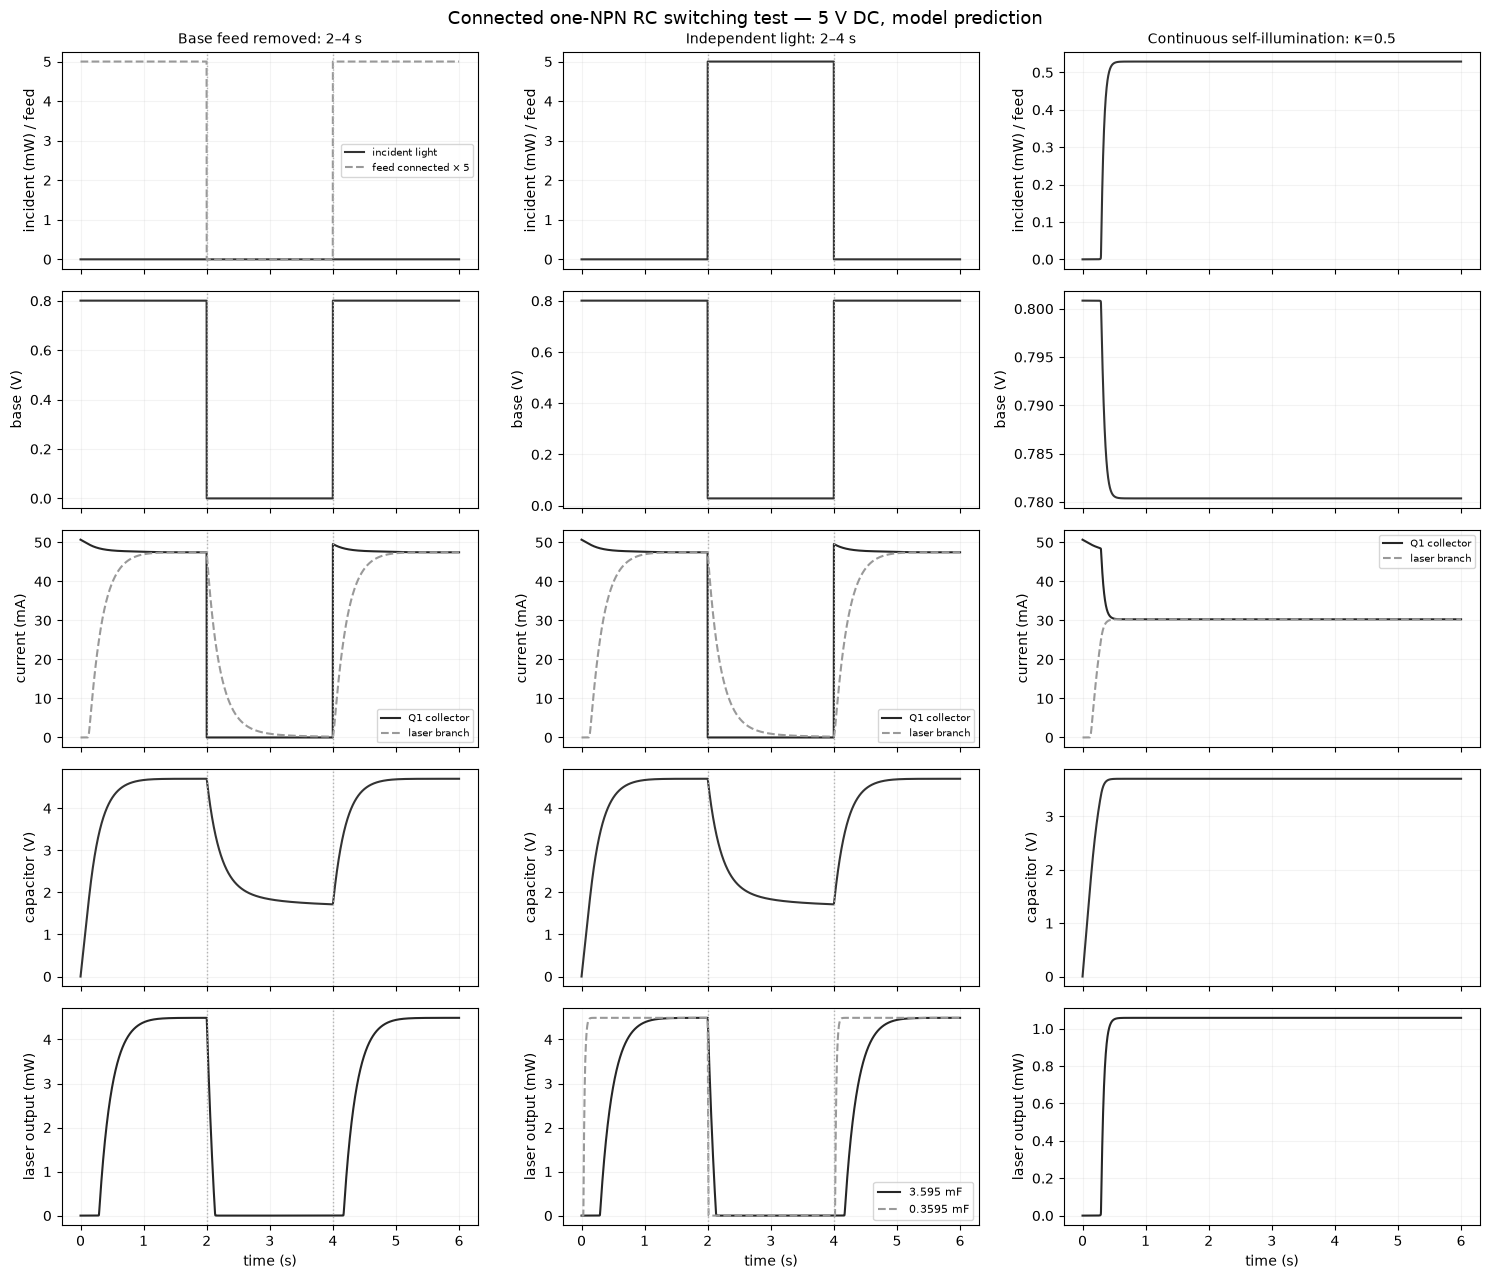

,switching check,passed
0,external light suppresses final output below 1...,True
1,darkness restores more than 99 percent output,True
2,Q1 current suppressed promptly under illumination,True
3,stored emitter energy sustains light immediate...,True
4,smaller capacitor shortens optical fall by abo...,True
5,step and tolerance refinement changes light by...,True
6,all algebraic base current balances close belo...,True
7,storage and collector remain within the DC sup...,True
8,laser remains within the inherited current mod...,True


**Connected switching result:** light reduces Q1 current promptly, but the capacitor keeps the laser emitting during discharge. With external light the optical 90–10% fall takes **105.7 ms**; the capacitor ten times smaller gives **10.6 ms**. Removing light restores bright output. Continuous self-illumination approaches **1.058 mW**, with a last-second peak-to-peak variation of **0 mW**. This candidate gives delayed optical decay, not sustained full-on/full-off oscillation or a thyristor latch. A single autonomous storage state with quasi-static detector/transistor laws does not provide a periodic orbit. The test implements a fixed-C physical candidate rather than the exact nonlinear thermal/carrier analogs.

In [6]:
from twin_components.rc_emitter_switching import RCEmitterSwitching
st=np.linspace(0,6,3001)
switch_model=RCEmitterSwitching(cap_F=fitted_C,devices=devices)
light=lambda s:.005 if 2<=s<4 else 0.
feed=lambda s:not (2<=s<4)
cut=switch_model.run(st,drive=feed,breaks=[2,4])
lit=switch_model.run(st,external=light,breaks=[2,4])
self_model=RCEmitterSwitching(cap_F=fitted_C,coupling=.5,devices=devices)
self_rc=self_model.run(st)
fast_model=RCEmitterSwitching(cap_F=fitted_C/10,devices=devices)
fast=fast_model.run(st,external=light,breaks=[2,4])
refined=switch_model.run(st,external=light,breaks=[2,4],rtol=2e-8,max_step=.0025)
switch_runs={'base_feed_removed':cut,'independent_illumination':lit,'continuous_self_illumination':self_rc,'ten_times_smaller_C':fast}
for name,f in switch_runs.items():f.to_csv(OUT/('switching_'+name+'.csv'),index=False)

bright=float(lit.loc[(lit.time_s>1.8)&(lit.time_s<2),'laser_W'].mean())
def crossing(f,start,end,level,rising):
    a=f.loc[(f.time_s>=start)&(f.time_s<=end),['time_s','laser_W']].to_numpy()
    z=a[:,1]-level
    hit=np.flatnonzero((z[:-1]<=0)&(z[1:]>0) if rising else (z[:-1]>=0)&(z[1:]<0))
    if not len(hit):return float('nan')
    j=hit[0];return float(a[j,0]+(a[j+1,0]-a[j,0])*(-z[j])/(z[j+1]-z[j]))
timing=[]
for name,f in [('feed removed',cut),('light applied',lit),('light applied, C/10',fast)]:
    t90=crossing(f,2,4,.9*bright,False);t10=crossing(f,2,4,.1*bright,False)
    on10=crossing(f,4,6,.1*bright,True);on90=crossing(f,4,6,.9*bright,True)
    timing.append(dict(test=name,off_90_to_10_ms=1000*(t10-t90),off_to_10_ms=1000*(t10-2),on_10_to_90_ms=1000*(on90-on10),on_to_90_ms=1000*(on90-4)))
timing_table=pd.DataFrame(timing);timing_table.to_csv(OUT/'switching_timing.csv',index=False)
display(timing_table)
late=self_rc.loc[self_rc.time_s>=5]
switch_checks={
 'external light suppresses final output below 1 percent':float(lit.loc[(lit.time_s>3.8)&(lit.time_s<4),'laser_W'].max())<.01*bright,
 'darkness restores more than 99 percent output':float(lit.laser_W.iloc[-1])>.99*bright,
 'Q1 current suppressed promptly under illumination':float(lit.loc[lit.time_s==2,'transistor_A'].iloc[0])<1e-6,
 'stored emitter energy sustains light immediately after inhibition':float(lit.loc[lit.time_s==2,'laser_W'].iloc[0])>.99*bright,
 'smaller capacitor shortens optical fall by about tenfold':abs(timing[1]['off_90_to_10_ms']/timing[2]['off_90_to_10_ms']-10)<.05,
 'step and tolerance refinement changes light by less than 0.01 percent full scale':float(np.max(abs(lit.laser_W-refined.laser_W)))/bright<1e-4,
 'all algebraic base current balances close below 1 nA':max(float(f.KCL_A.abs().max()) for f in switch_runs.values())<1e-9,
 'storage and collector remain within the DC supply rails':all(f.capacitor_V.min()>-1e-8 and f.capacitor_V.max()<5 for f in switch_runs.values()),
 'laser remains within the inherited current model domain':max(float(f.laser_A.max()) for f in switch_runs.values())<.1}
assert all(switch_checks.values()),switch_checks
switch_summary=dict(checks={k:bool(v) for k,v in switch_checks.items()},timing=timing,
    bright_output_mW=bright*1e3,self_feedback_final_mW=float(self_rc.laser_W.iloc[-1]*1e3),
    self_feedback_late_peak_to_peak_mW=float(np.ptp(late.laser_W)*1e3),
    max_refinement_normalized_error=float(np.max(abs(lit.laser_W-refined.laser_W)))/bright,
    supply='ideal 5 V DC',capacitor_F=fitted_C,carrier_dynamics='quasi-static fitted BPW34',
    hardware_validated=False,exact_thermal_equivalent=False)
(OUT/'switching_results_summary.json').write_text(json.dumps(switch_summary,indent=2),encoding='utf-8')
fig,axs=plt.subplots(5,3,figsize=(15,13),sharex=True)
for col,(title,f) in enumerate([('Base feed removed: 2–4 s',cut),('Independent light: 2–4 s',lit),('Continuous self-illumination: κ=0.5',self_rc)]):
    ax=axs[:,col]
    ax[0].plot(f.time_s,f.incident_W*1e3,color='.2',label='incident light')
    if col==0:
        ax[0].plot(f.time_s,f.drive_connected.astype(float)*5,color='.6',ls='--',label='feed connected × 5')
        ax[0].legend(fontsize=7)
    ax[0].set_title(title,fontsize=10)
    ax[1].plot(f.time_s,f.base_V,color='.2')
    ax[2].plot(f.time_s,f.transistor_A*1e3,color='.15',label='Q1 collector')
    ax[2].plot(f.time_s,f.laser_A*1e3,color='.6',ls='--',label='laser branch');ax[2].legend(fontsize=7)
    ax[3].plot(f.time_s,f.capacitor_V,color='.2')
    ax[4].plot(f.time_s,f.laser_W*1e3,color='.15',label='3.595 mF')
    if col==1:
        ax[4].plot(fast.time_s,fast.laser_W*1e3,color='.6',ls='--',label='0.3595 mF');ax[4].legend(fontsize=8)
    if col<2:
        for a in ax:
            for edge in [2,4]:a.axvline(edge,color='.7',ls=':',lw=1)
    for a,label in zip(ax,['incident (mW) / feed','base (V)','current (mA)','capacitor (V)','laser output (mW)']):
        a.set_ylabel(label);a.grid(alpha=.15)
    ax[-1].set_xlabel('time (s)')
fig.suptitle('Connected one-NPN RC switching test — 5 V DC, model prediction',fontsize=13)
fig.tight_layout();save(fig,'nightlight_rc_connected_switching')
display(pd.DataFrame({'switching check':switch_checks.keys(),'passed':switch_checks.values()}))
display(Markdown(f'**Connected switching result:** light reduces Q1 current promptly, but the capacitor keeps the laser emitting during discharge. With external light the optical 90–10% fall takes **{timing[1]["off_90_to_10_ms"]:.1f} ms**; the capacitor ten times smaller gives **{timing[2]["off_90_to_10_ms"]:.1f} ms**. Removing light restores bright output. Continuous self-illumination approaches **{self_rc.laser_W.iloc[-1]*1e3:.3f} mW**, with a last-second peak-to-peak variation of **{np.ptp(late.laser_W)*1e3:.2g} mW**. This candidate gives delayed optical decay, not sustained full-on/full-off oscillation or a thyristor latch. A single autonomous storage state with quasi-static detector/transistor laws does not provide a periodic orbit. The test implements a fixed-C physical candidate rather than the exact nonlinear thermal/carrier analogs.'))


## 6. 60 Hz AC: connected switching and self-feedback

The generator is **5 V peak, 60 Hz, zero DC offset**, not 5 V RMS. This test retains the 3.595 mF capacitor across the laser-plus-33 Ω branch. A DC supply cannot simply be replaced by a bipolar source while assuming the floating laser return stays above ground. The AC candidate therefore includes explicit protective/isolation diodes. It is a proposed topology, not a reconstruction of unverified board wiring.

```text
5 sin(2π60t) ── Dsource → ── E ──┬── laser + 33 Ω ──┬── N ── Doutput → ── Q1 collector
                                └── C = 3.595 mF ───┘                       Q1 emitter ── GND
E ── 10 kΩ ── T ── Dbase → ── Q1 base ── 1 kΩ ── BPW34 cathode
                                  │                 BPW34 anode ── GND
                                100 kΩ
                                  │
                                 GND
E ── 1 MΩ ── GND
```

Dsource blocks the negative generator half-cycle; Doutput isolates the transistor from the floating storage return when E falls. A reverse diode across the laser branch is also included, anode N and cathode E. Dbase prevents the trigger feed from drawing charge backward. All diodes use the inherited illustrative Shockley law (Is=10 nA, nVt≈27 mV), not a newly fitted part. The 1 MΩ rail bleed is explicit. There is no additional base or detector capacitor and no inductor. Intrinsic fitted device capacitances and the inherited 10–110 pF nodal capacitance priors are retained. Fast switching and diode parasitics remain unvalidated. The generator is an ideal voltage source; a real generator's output resistance and current limit can reduce the predicted light.

Six nodal voltages are integrated (base B, collector X, trigger T, rail E, detector D, floating return N). With v=E−N, the large storage capacitor contributes C to the E and N diagonal entries and −C to their mutual entries in the nodal capacitance matrix. Thus its charge cannot be reset at an AC zero crossing. Source current, Q1 collector current and laser current are solved separately; the capacitor supplies their difference. Negative N is allowed; it is distinct from Q1 collector X.

Cold-start darkness and continuous self-illumination (κ=0.5) start with every node at zero. A separate switching run starts with an explicitly precharged 3.8 V capacitor (E=0, N=−3.8 V, other nodes zero); 5 mW external illumination is applied from 0.05–0.25 s, with the self-return blocked. This tests whether AC can restore light after inhibition, without waiting for cold startup. A control removes only the macroscopic emitter capacitor (C=0); intrinsic/nodal capacitances remain. Repetition classifications apply only to the sampled finite window, with full waveforms compared at matching generator phase. Numerical checks do not presume that a proposed circuit must lase or recover.


AC: external illumination experiment
AC: uncharged dark startup
AC: continuous self-feedback experiment
AC: no macroscopic storage control


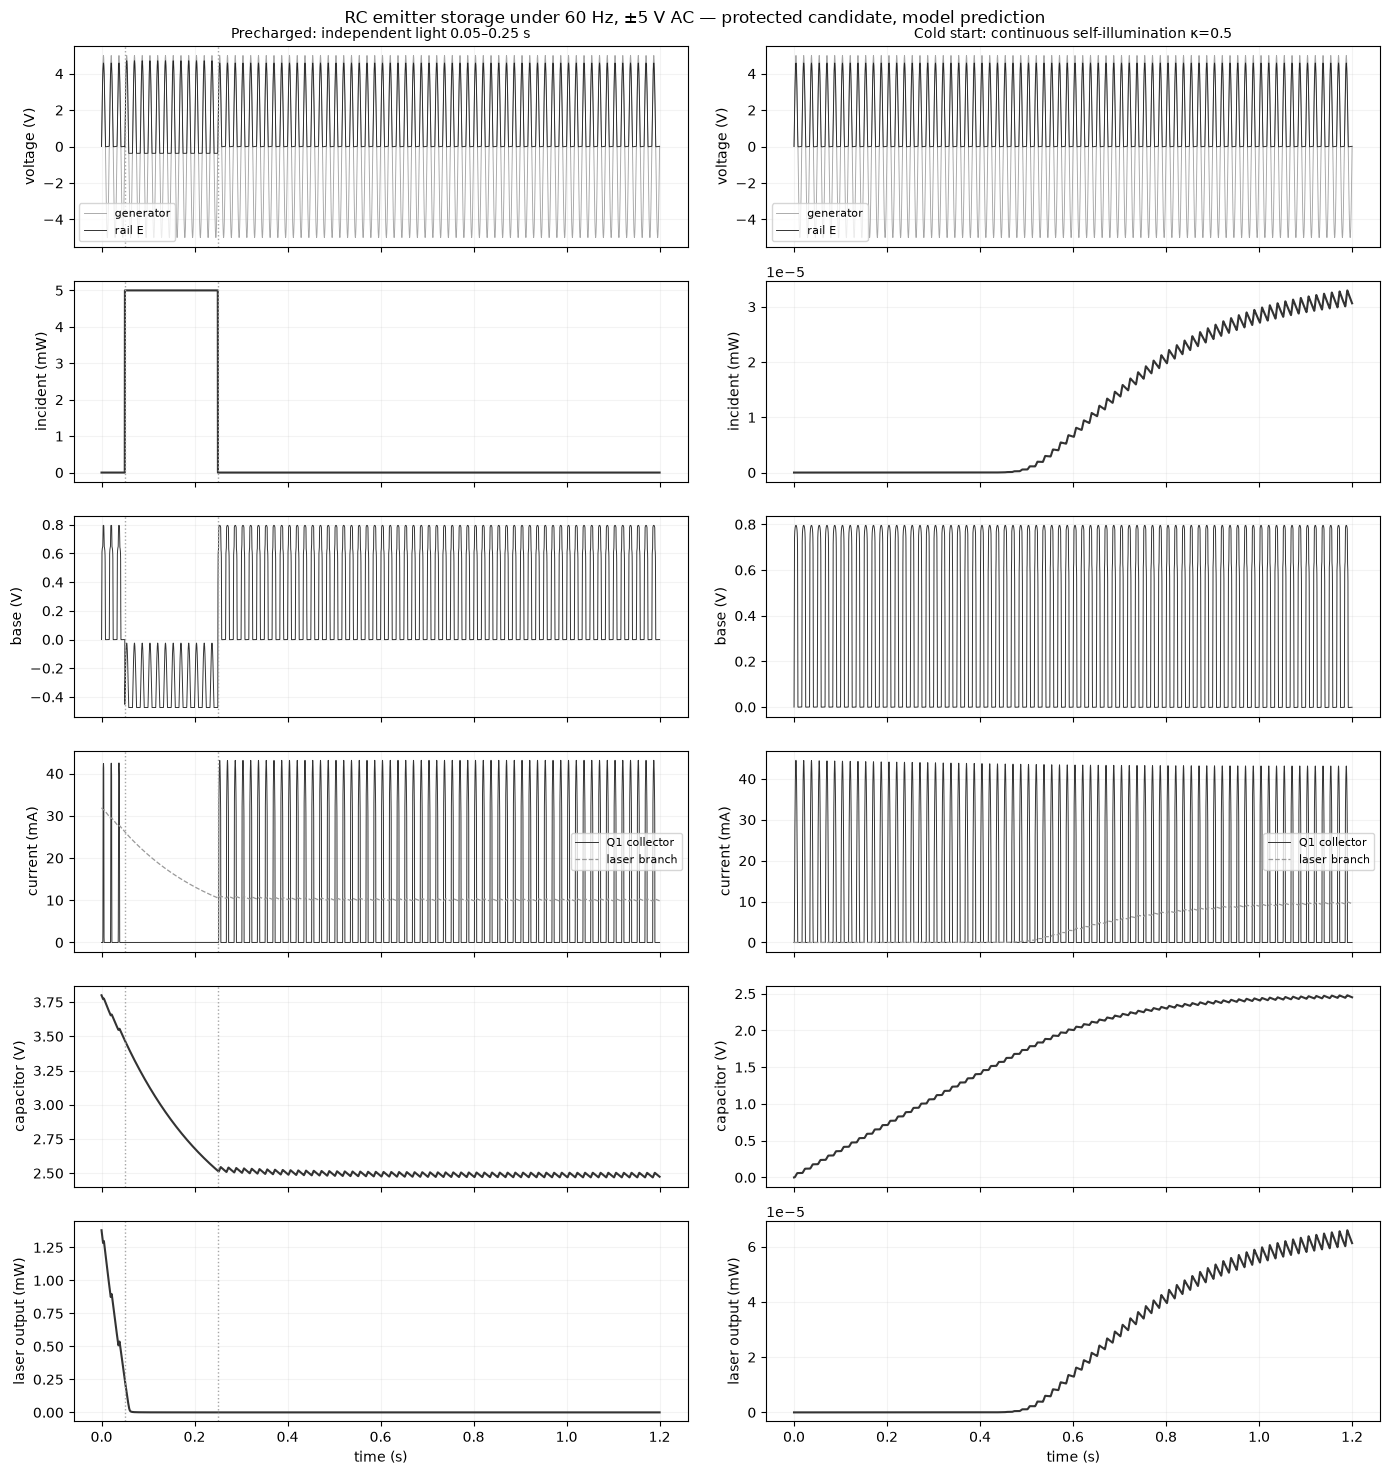

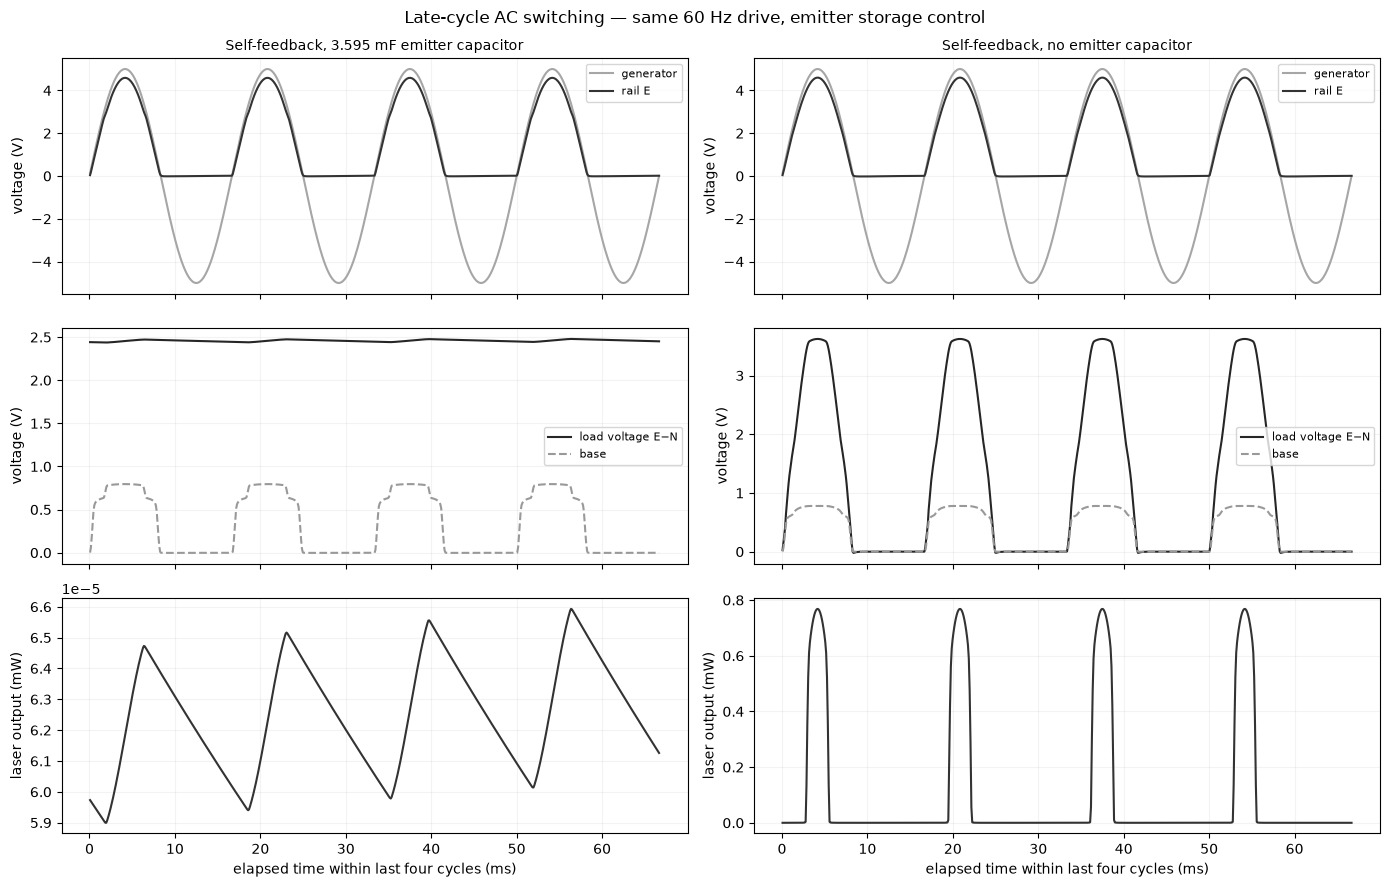

,dark_before_mW,illuminated_end_mW,dark_after_mW,cold_dark_late_mW,self_late_mean_mW,self_late_peak_mW,cold_late_mean_collector_mA,cold_late_mean_laser_mA,source_negative_peak_V,min_floating_return_V,min_Q1_collector_V,refinement_normalized_error
0,0.805082,0.00009,0.000067,0.000062,0.00006,0.000066,10.144066,9.417767,-5.0,-2.486238,-0.349843,7.047350e-07


,AC check,passed
0,generator has positive and negative 5 V peaks,True
1,cold startup begins without stored charge,True
2,precharge is explicit rather than hidden suppl...,True
3,AC integration refinement changes late optical...,True
4,all AC nodal current balances close below 10 nA,True
5,laser currents remain within inherited model d...,True
6,storage laser branch avoids appreciable revers...,True
7,stored-energy path permits a floating negative...,True


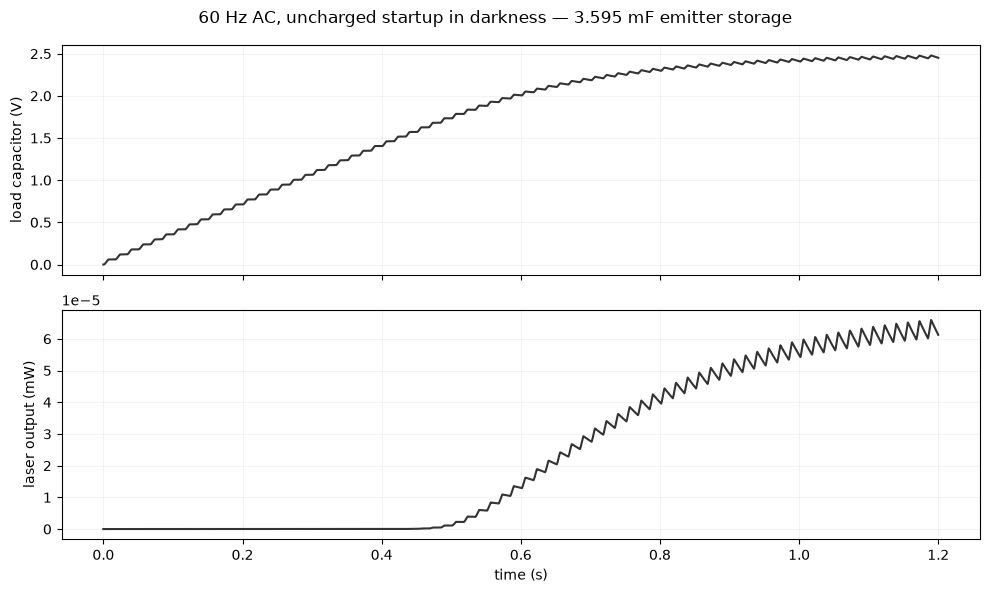

**60 Hz result:** precharged mean output before external light is **0.805 mW**; at the end of illumination it is **9.02e-05 mW**, and after light removal it reaches **6.72e-05 mW** in the stated window. The uncharged dark-start late mean is **6.21e-05 mW**; the self-feedback late mean is **6.05e-05 mW**. Bright-lasing criteria (0.1 mW as an explicit reporting level, not a model switch) are recorded separately from numerical checks. Matching-phase waveform comparisons give **None** as the smallest repeated number of drive cycles within 1% in this finite window (None means unresolved/transient). Near-dark periodicity is not a useful bright optical oscillation. The capacitor requires charge over the whole cycle, while the isolated Q1 charging path is available for part of the positive half-cycle. Compare the separate collector-current pulses and laser-branch current. The no-capacitor close-up shows whether AC pulses lase without that storage burden. No chaos or hardware performance is established.

In [7]:
from twin_components.rc_emitter_ac import RCEmitterAC
at=np.linspace(0,1.2,12001)
aclight=lambda s:.005 if .05<=s<.25 else 0.
ac_ind_model=RCEmitterAC(cap_F=fitted_C,devices=devices,external=aclight)
print('AC: external illumination experiment',flush=True)
ac_ind=ac_ind_model.run(at,initial=[0,0,0,0,0,-3.8],breaks=[.05,.25],max_step=2e-4)
ac_ind.to_csv(OUT/'switching_ac_independent.csv',index=False)
print('AC: uncharged dark startup',flush=True)
ac_cold_model=RCEmitterAC(cap_F=fitted_C,devices=devices)
ac_cold=ac_cold_model.run(at,max_step=2e-4)
ac_cold.to_csv(OUT/'switching_ac_cold_dark.csv',index=False)
ac_self_model=RCEmitterAC(cap_F=fitted_C,coupling=.5,devices=devices)
print('AC: continuous self-feedback experiment',flush=True)
ac_self=ac_self_model.run(at,max_step=2e-4)
ac_self.to_csv(OUT/'switching_ac_self.csv',index=False)
print('AC: no macroscopic storage control',flush=True)
ac_zero_model=RCEmitterAC(cap_F=0.,coupling=.5,devices=devices)
ac_zero=ac_zero_model.run(np.linspace(0,.4,4001),max_step=2e-4)
ac_zero.to_csv(OUT/'switching_ac_no_emitter_cap.csv',index=False)
state_cols=['base_V','collector_V','trigger_V','rail_V','diode_V','return_V']
init=ac_self[state_cols].iloc[-1].to_numpy();ct=np.linspace(1.2,1.3,1001)
ac_check=ac_self_model.run(ct,initial=init,max_step=2e-4)
ac_fine=ac_self_model.run(ct,initial=init,max_step=1e-4,rtol=2e-7)
scale=max(float(ac_check.laser_W.max()),1e-12)
ac_refine=float(np.max(abs(ac_check.laser_W-ac_fine.laser_W))/scale)
ac_late_cycles,ac_repetition=cycle_metrics(ac_self,discard_cycles=48,samples_per_cycle=160)
ac_late_cycles.to_csv(OUT/'switching_ac_self_cycles.csv',index=False)
zero_cycles,zero_repetition=cycle_metrics(ac_zero,discard_cycles=12,samples_per_cycle=160)
zero_cycles.to_csv(OUT/'switching_ac_zero_cycles.csv',index=False)
def mean_power(f,a,b):return float(f.loc[(f.time_s>=a)&(f.time_s<b),'laser_W'].mean())
ac_measure=dict(dark_before_mW=mean_power(ac_ind,0,.05)*1e3,
    illuminated_end_mW=mean_power(ac_ind,.2,.25)*1e3,
    dark_after_mW=mean_power(ac_ind,1.1,1.2)*1e3,
    cold_dark_late_mW=mean_power(ac_cold,1.1,1.2)*1e3,
    self_late_mean_mW=mean_power(ac_self,1.,1.2)*1e3,
    self_late_peak_mW=float(ac_self.loc[ac_self.time_s>=1.,'laser_W'].max()*1e3),
    cold_late_mean_collector_mA=float(ac_cold.loc[ac_cold.time_s>=1.,'collector_A'].mean()*1e3),
    cold_late_mean_laser_mA=float(ac_cold.loc[ac_cold.time_s>=1.,'laser_A'].mean()*1e3),
    source_negative_peak_V=float(ac_ind.raw_generator_V.min()),
    min_floating_return_V=float(ac_self.return_V.min()),
    min_Q1_collector_V=float(ac_self.collector_V.min()),
    refinement_normalized_error=ac_refine)
ac_checks={
 'generator has positive and negative 5 V peaks':abs(ac_ind.raw_generator_V.max()-5)<.001 and abs(ac_ind.raw_generator_V.min()+5)<.001,
 'cold startup begins without stored charge':abs(float(ac_cold.capacitor_V.iloc[0]))<1e-12,
 'precharge is explicit rather than hidden supply offset':abs(float(ac_ind.capacitor_V.iloc[0])-3.8)<1e-12,
 'AC integration refinement changes late optical waveform by less than 0.5 percent':ac_refine<.005,
 'all AC nodal current balances close below 10 nA':max(float(f.max_KCL_A.max()) for f in [ac_ind,ac_self,ac_zero,ac_cold])<1e-8,
 'laser currents remain within inherited model domain':max(float(f.laser_A.max()) for f in [ac_ind,ac_self,ac_zero,ac_cold])<.1,
 'storage laser branch avoids appreciable reverse voltage':min(float(f.capacitor_V.min()) for f in [ac_ind,ac_self])>-.8,
 'stored-energy path permits a floating negative return':float(ac_self.return_V.min())<-.1}
assert all(ac_checks.values()),(ac_checks,ac_measure)
ac_summary=dict(measurements=ac_measure,self_repetition=ac_repetition,no_emitter_cap_repetition=zero_repetition,
    checks={k:bool(v) for k,v in ac_checks.items()},source_peak_V=5,frequency_Hz=60,offset_V=0,
    capacitor_F=fitted_C,hardware_validated=False,extra_diodes_explicit=True,
    cold_start_bright_lasing_in_window=ac_measure['cold_dark_late_mW']>.1,
    restores_bright_lasing_in_window=ac_measure['dark_after_mW']>.1)
(OUT/'switching_ac_results_summary.json').write_text(json.dumps(ac_summary,indent=2),encoding='utf-8')
fig,axs=plt.subplots(6,2,figsize=(14,15),sharex=True)
for col,(title,f) in enumerate([('Precharged: independent light 0.05–0.25 s',ac_ind),('Cold start: continuous self-illumination κ=0.5',ac_self)]):
    ax=axs[:,col]
    ax[0].plot(f.time_s,f.raw_generator_V,color='.65',lw=.65,label='generator')
    ax[0].plot(f.time_s,f.rail_V,color='.15',lw=.65,label='rail E');ax[0].legend(fontsize=8);ax[0].set_title(title,fontsize=10)
    ax[1].plot(f.time_s,f.incident_W*1e3,color='.2')
    ax[2].plot(f.time_s,f.base_V,color='.2',lw=.7)
    ax[3].plot(f.time_s,f.collector_A*1e3,color='.2',lw=.7,label='Q1 collector')
    ax[3].plot(f.time_s,f.laser_A*1e3,color='.6',lw=.9,ls='--',label='laser branch');ax[3].legend(fontsize=8)
    ax[4].plot(f.time_s,f.capacitor_V,color='.2')
    ax[5].plot(f.time_s,f.laser_W*1e3,color='.2')
    if col==0:
        for a in ax:
            for edge in [.05,.25]:a.axvline(edge,color='.65',ls=':',lw=1)
    for a,label in zip(ax,['voltage (V)','incident (mW)','base (V)','current (mA)','capacitor (V)','laser output (mW)']):a.set_ylabel(label);a.grid(alpha=.15)
    ax[-1].set_xlabel('time (s)')
fig.suptitle('RC emitter storage under 60 Hz, ±5 V AC — protected candidate, model prediction')
fig.tight_layout();save(fig,'nightlight_rc_ac_switching')
fig,axs=plt.subplots(3,2,figsize=(14,9),sharex=True)
for col,(title,f,end) in enumerate([('Self-feedback, 3.595 mF emitter capacitor',ac_self,1.2),('Self-feedback, no emitter capacitor',ac_zero,.4)]):
    close=f.loc[f.time_s>=end-4/60];phase_t=(close.time_s-(end-4/60))*1e3;ax=axs[:,col]
    ax[0].plot(phase_t,close.raw_generator_V,color='.65',label='generator');ax[0].plot(phase_t,close.rail_V,color='.2',label='rail E');ax[0].legend(fontsize=8);ax[0].set_title(title,fontsize=10)
    ax[1].plot(phase_t,close.capacitor_V,color='.15',label='load voltage E−N');ax[1].plot(phase_t,close.base_V,color='.6',ls='--',label='base');ax[1].legend(fontsize=8)
    ax[2].plot(phase_t,close.laser_W*1e3,color='.2')
    for a,label in zip(ax,['voltage (V)','voltage (V)','laser output (mW)']):a.set_ylabel(label);a.grid(alpha=.15)
    ax[-1].set_xlabel('elapsed time within last four cycles (ms)')
fig.suptitle('Late-cycle AC switching — same 60 Hz drive, emitter storage control')
fig.tight_layout();save(fig,'nightlight_rc_ac_cycle_closeup')
display(pd.DataFrame([ac_measure]));display(pd.DataFrame({'AC check':ac_checks.keys(),'passed':ac_checks.values()}))
fig,axs=plt.subplots(2,1,figsize=(10,6),sharex=True)
axs[0].plot(ac_cold.time_s,ac_cold.capacitor_V,color='.2');axs[0].set_ylabel('load capacitor (V)')
axs[1].plot(ac_cold.time_s,ac_cold.laser_W*1e3,color='.2');axs[1].set_ylabel('laser output (mW)');axs[1].set_xlabel('time (s)')
for ax in axs:ax.grid(alpha=.15)
fig.suptitle('60 Hz AC, uncharged startup in darkness — 3.595 mF emitter storage')
fig.tight_layout();save(fig,'nightlight_rc_ac_cold_start')
display(Markdown(f'**60 Hz result:** precharged mean output before external light is **{ac_measure["dark_before_mW"]:.3f} mW**; at the end of illumination it is **{ac_measure["illuminated_end_mW"]:.3g} mW**, and after light removal it reaches **{ac_measure["dark_after_mW"]:.3g} mW** in the stated window. The uncharged dark-start late mean is **{ac_measure["cold_dark_late_mW"]:.3g} mW**; the self-feedback late mean is **{ac_measure["self_late_mean_mW"]:.3g} mW**. Bright-lasing criteria (0.1 mW as an explicit reporting level, not a model switch) are recorded separately from numerical checks. Matching-phase waveform comparisons give **{ac_repetition["smallest_repeated_cycles"]}** as the smallest repeated number of drive cycles within 1% in this finite window (None means unresolved/transient). Near-dark periodicity is not a useful bright optical oscillation. The capacitor requires charge over the whole cycle, while the isolated Q1 charging path is available for part of the positive half-cycle. Compare the separate collector-current pulses and laser-branch current. The no-capacitor close-up shows whether AC pulses lase without that storage burden. No chaos or hardware performance is established.'))


## Checks and implications for the next physical RC candidate

The exact reference blocks are mathematical equivalents of the printed equations. They require the stated nonlinear functions and readouts. The ordinary fixed-RC values are local approximations. The laser parallel-capacitor and loaded-base tests are separate physical unit tests, not a claim that a complete one-transistor RC feedback board reproduces the reference nightlight.

The useful architecture requirement is now explicit: put the principal thermal-memory function in the **emitter/drive path**, keep the carrier path fast unless measurements justify a slower model, isolate stored emitter energy from the light-controlled inhibition path, and account for laser energy supply after switching. Any RC laser implementation still needs its nonlinear readout, loading, available charging current and switching behavior fitted; an RC pair alone does not reproduce the SCR's latched state.

An archived 240-frame/s filament-brightness curve was found at `00_archive/07_audio_bulb_experiment/Legacy/Bulb/brightness_curve.csv`. It is not used to identify parameters here because bulb identity, exposure/gamma and conversion from pixel brightness to radiated power are not established. Neither archives nor raw experimental data are modified. No hardware is controlled.


In [8]:
matched_target=matched.laser_W.to_numpy()/matched.laser_W.iloc[0]
fixed_RMS=float(np.sqrt(fit.fun))
checks={
 'temperature-state RC reproduces large thermal trajectory':thermal_errors['RC_temperature']<1e-3,
 'power-state RC reproduces large thermal trajectory':thermal_errors['RC_power']<1e-3,
 'all mapped differential capacitances remain positive':all((f.temperature_cap_F>0).all() and (f.power_cap_F>0).all() for f in large.values()),
 'local voltage-step RC approximation within 1 percent':linear_error<.01,
 'carrier RC reproduces original carrier step':carrier_error<1e-8,
 'rescaled carrier lifetime preserves declared DC readout':dc_curve_error<1e-10,
 'carrier RC time equals printed lifetime':abs(carrier.R*carrier.C/tau_n-1)<1e-12,
 'nonlinear laser capacitor matches scaled thermal cooling':nonlinear_error<1e-4,
 'fitted loaded base pole matches target time':abs(slowest(base_C)*tau+1)<1e-5,
 'small loaded-base perturbation follows local RC within 1 percent RMS':probe_errors[str(20e-6)]<.01,
 'laser unit-bench current stays within demonstration domain':max(lw.laser_A.max(),fixed.laser_A.max(),matched.laser_A.max())<.1,
 'raw historical data unchanged':hashlib.sha256(raw.read_bytes()).hexdigest()==raw_hash}
assert all(checks.values()),checks
summary=dict(reference_parameters=asdict(thermal.p),operating_point=op,thermal_equivalence_max_error_K=thermal_errors,
    local_thermal_step_relative_error=linear_error,carrier_step_error=carrier_error,carrier_RC_F=carrier.C,
    fixed_laser_cap_F=fitted_C,fixed_laser_normalized_cooling_RMS=fixed_RMS,
    nonlinear_laser_normalized_cooling_RMS=nonlinear_error,
    nonlinear_laser_cap_initial_F=float(matched.required_capacitance_F.iloc[0]),nonlinear_laser_cap_final_F=float(matched.required_capacitance_F.iloc[-1]),
    rise_comparison=rise_table.to_dict('records'),loaded_base_C_F=base_C,loaded_base_effective_R_ohm=tau/base_C,
    loaded_base_probe_errors=probe_errors,loaded_RC_AC_finite_window=ac_info,
    checks={k:bool(v) for k,v in checks.items()},exact_blocks_require_nonlinear_elements=True,
    complete_RC_laser_feedback_equivalence=False,hardware_validated=False,reference_chaos_reproduced=False)
(OUT/'results_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
display(pd.DataFrame({'check':checks.keys(),'passed':checks.values()}))
display(Markdown(f'**Finding:** exact nonlinear RC analogs reproduce the reference thermal trajectories to below 0.001 K and the normalized carrier equation to numerical precision. The local hot power-memory block is **10 kΩ / {op["power_state_hot_C_F"]*1e6:.2f} µF**, with a **{op["cooling_time_s"]*1e3:.2f} ms** cooling pole. A fixed capacitor fitted across the laser is **{fitted_C*1e3:.2f} mF** but leaves **{fixed_RMS*100:.1f}%** full-scale normalized RMS cooling mismatch and does not reproduce warm-up under the 35 mA charging limit. The exact laser-cooling analog instead needs a strongly varying capacitance. The actual transistor-base local-pole fit requires approximately **{base_C*1e6:.0f} µF**, not the abstract block\'s 2.43 µF. These results define the block requirements; they do not yet validate a complete physical RC replacement for the nightlight.'))


,check,passed
0,temperature-state RC reproduces large thermal ...,True
1,power-state RC reproduces large thermal trajec...,True
2,all mapped differential capacitances remain po...,True
3,local voltage-step RC approximation within 1 p...,True
4,carrier RC reproduces original carrier step,True
5,rescaled carrier lifetime preserves declared D...,True
6,carrier RC time equals printed lifetime,True
7,nonlinear laser capacitor matches scaled therm...,True
8,fitted loaded base pole matches target time,True
9,small loaded-base perturbation follows local R...,True


**Finding:** exact nonlinear RC analogs reproduce the reference thermal trajectories to below 0.001 K and the normalized carrier equation to numerical precision. The local hot power-memory block is **10 kΩ / 2.43 µF**, with a **24.32 ms** cooling pole. A fixed capacitor fitted across the laser is **3.60 mF** but leaves **12.6%** full-scale normalized RMS cooling mismatch and does not reproduce warm-up under the 35 mA charging limit. The exact laser-cooling analog instead needs a strongly varying capacitance. The actual transistor-base local-pole fit requires approximately **724 µF**, not the abstract block's 2.43 µF. These results define the block requirements; they do not yet validate a complete physical RC replacement for the nightlight.

## Rerun

Run all nine code cells in the project environment. The notebook regenerates the unit tests, laser cooling fit, loaded-base pole fit and finite-window AC check. Reusable equations are in `twin_components/nightlight_rc_equivalents.py`; physical diode/NPN/laser tests reuse `single_transistor_rlc.py` with L=0. Files are saved to `twin_output/nightlight_rc_blocks`; figures to `06_figures/nightlight_rc_*`.

The reference's controlled sources/nonlinear capacitors are model elements, not hidden components in a claimed passive circuit. Sources and numerical ambiguities are documented above. Existing RLC and component notebooks are preserved. No diode/coil/SCR substitutions, dataset fits, public publication or instrument actions are performed.


## AC control sampling verification

The first no-capacitor control above uses 100 µs output samples, or 166⅔ samples per 60 Hz period. Interpolating its sharp pulse edges onto the phase-comparison grid can create a three-cycle numerical pattern. That result must not be interpreted as a period-three bifurcation. The check below reruns the same physical control with **1000 output samples per drive period**, then repeats it with a smaller solver step and tighter tolerance. The stored AC summary is updated with the refined classification; the original comparison remains recorded as `coarse_no_emitter_cap_repetition`. The main capacitive trajectories are unchanged. This extra check is needed because the initial late-waveform refinement tested the capacitive case, whose optical edges are much slower.


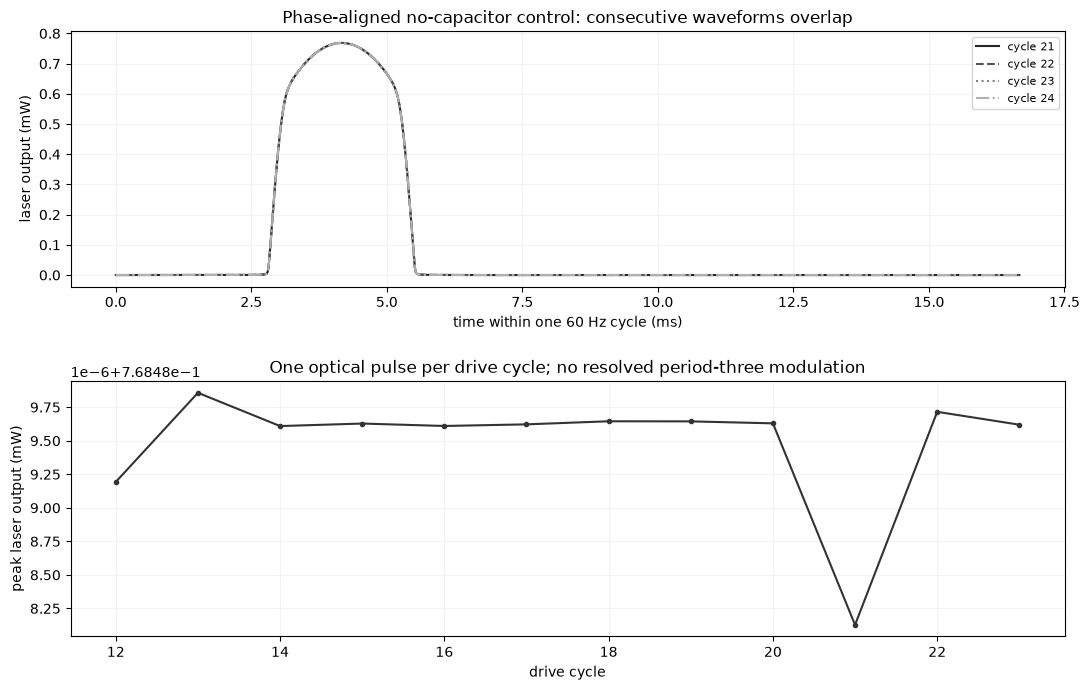

,sampling check,passed
0,phase-aligned control repeats every drive period,True
1,tighter control solve also repeats every drive...,True
2,control waveform refinement changes output by ...,True


**Verified control:** one optical pulse per 60 Hz drive cycle, peaking at approximately **0.768 mW**. Consecutive waveforms differ by **0.009911%** of peak output; tighter integration changes the late optical waveform by **0.009989%**. The earlier apparent three-cycle repetition was caused by the output sampling/interpolation. This control is ordinary AC-forced pulsing, not evidence of a new bifurcation. The 3.595 mF case remains nearly dark in its finite window.

In [9]:
from pathlib import Path
import os,json,sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown
CHECK_ROOT=Path(os.environ.get('TWIN_PROJECT_ROOT','.'))
sys.path.insert(0,os.environ.get('TWIN_COMPONENT_PATH',str(CHECK_ROOT/'03_code')))
from twin_components.rc_emitter_ac import RCEmitterAC
from twin_components.delayed_latch_optics import cycle_metrics
CHECK_OUTPUT=Path(os.environ.get('TWIN_OUTPUT_ROOT',str(CHECK_ROOT)))
CHECK_OUT=CHECK_OUTPUT/'03_code/notebooks/twin_output/nightlight_rc_blocks'
CHECK_FIG=CHECK_OUTPUT/'06_figures'
aligned_t=np.arange(24001)/(60*1000)
aligned_model=RCEmitterAC(cap_F=0.,coupling=.5)
aligned=aligned_model.run(aligned_t,max_step=2e-4)
aligned_fine=aligned_model.run(aligned_t,max_step=1e-4,rtol=2e-7)
aligned.to_csv(CHECK_OUT/'switching_ac_no_emitter_cap_aligned.csv',index=False)
aligned_cycles,aligned_repetition=cycle_metrics(aligned,discard_cycles=12,samples_per_cycle=1000)
fine_cycles,fine_repetition=cycle_metrics(aligned_fine,discard_cycles=12,samples_per_cycle=1000)
aligned_cycles.to_csv(CHECK_OUT/'switching_ac_aligned_cycles.csv',index=False)
late=aligned_t>=.2
control_refinement=float(np.max(abs(aligned.laser_W.to_numpy()[late]-aligned_fine.laser_W.to_numpy()[late]))/aligned_fine.laser_W.to_numpy()[late].max())
sampling_checks={
 'phase-aligned control repeats every drive period':aligned_repetition['smallest_repeated_cycles']==1,
 'tighter control solve also repeats every drive period':fine_repetition['smallest_repeated_cycles']==1,
 'control waveform refinement changes output by less than 0.5 percent':control_refinement<.005}
assert all(sampling_checks.values()),(sampling_checks,aligned_repetition,fine_repetition,control_refinement)
summary_path=CHECK_OUT/'switching_ac_results_summary.json'
ac_record=json.loads(summary_path.read_text())
ac_record['coarse_no_emitter_cap_repetition']=ac_record['no_emitter_cap_repetition']
ac_record['no_emitter_cap_repetition']=aligned_repetition
ac_record['aligned_control_tighter_repetition']=fine_repetition
ac_record['control_sampling_note']='The coarse 100 us output grid produced an apparent three-cycle pattern. Output at 1000 samples per 60 Hz cycle resolves period-one forcing; this is not a verified period-three regime.'
ac_record['control_refinement_normalized_error']=control_refinement
ac_record['sampling_checks']={k:bool(v) for k,v in sampling_checks.items()}
summary_path.write_text(json.dumps(ac_record,indent=2),encoding='utf-8')
fig,axs=plt.subplots(2,1,figsize=(11,7))
for j in range(20,24):
    a=aligned.iloc[j*1000:(j+1)*1000+1]
    axs[0].plot((a.time_s-j/60)*1e3,a.laser_W*1e3,color=str(.15+.18*(j-20)),ls=['-','--',':','-.'][j-20],label=f'cycle {j+1}')
axs[0].set(xlabel='time within one 60 Hz cycle (ms)',ylabel='laser output (mW)',title='Phase-aligned no-capacitor control: consecutive waveforms overlap');axs[0].legend(fontsize=8)
axs[1].plot(aligned_cycles.cycle,aligned_cycles.peak_mW,color='.2',marker='o',ms=3)
axs[1].set(xlabel='drive cycle',ylabel='peak laser output (mW)',title='One optical pulse per drive cycle; no resolved period-three modulation')
for ax in axs:ax.grid(alpha=.15)
fig.tight_layout()
for ext in ['png','svg']:fig.savefig(CHECK_FIG/('nightlight_rc_ac_sampling_verification.'+ext),dpi=180,bbox_inches='tight')
plt.show()
display(pd.DataFrame({'sampling check':sampling_checks.keys(),'passed':sampling_checks.values()}))
display(Markdown(f'**Verified control:** one optical pulse per 60 Hz drive cycle, peaking at approximately **{aligned.laser_W.max()*1e3:.3f} mW**. Consecutive waveforms differ by **{aligned_repetition["waveform_relative_errors"]["1"]*100:.4g}%** of peak output; tighter integration changes the late optical waveform by **{control_refinement*100:.4g}%**. The earlier apparent three-cycle repetition was caused by the output sampling/interpolation. This control is ordinary AC-forced pulsing, not evidence of a new bifurcation. The 3.595 mF case remains nearly dark in its finite window.'))
